### Trend-Following with 200-Day SMA & Volatility Sizing

Instead of holding a fixed position size, scaling position size inversely to volatility produces smooth, steady compounding and significantly cuts downside variance.

#### Core Logic:
* **Trend Filter:** Go long when the asset's close is strictly above its 200-day SMA.
* **Volatility Sizing:** Target a constant annualized volatility (e.g., 10%) by sizing exposure inversely to rolling 20-day realized volatility:

$$\text{Target Weight} = \min\left(1.0, \frac{\sigma_{\text{target}}}{\sigma_{\text{realized}}}\right)$$

In [26]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yfinance as yf

# 1. Fetch data & run strategy
df = yf.download("SPY", start="2023-01-01", progress=False)
df.columns = df.columns.droplevel(1)

df["SMA200"] = df["Close"].rolling(window=200).mean()
df["Daily_Ret"] = df["Close"].pct_change()
df["Vol20"] = df["Daily_Ret"].rolling(window=20).std() * np.sqrt(252)

# Volatility targeting
# target_vol = df["Daily_Ret"].std() * np.sqrt(252)
# target_vol = df["Vol20"].mean()
target_vol = 0.10
print(f"Target Volatility: {target_vol:.4f}")

df["Raw_Weight"] = (target_vol / df["Vol20"]).clip(lower=0.0, upper=1.0)
df["Position"] = np.where(df["Close"] > df["SMA200"], df["Raw_Weight"], 0.0)
df["Strategy_Ret"] = df["Position"].shift(1) * df["Daily_Ret"]

df_clean = df.dropna(subset=["Strategy_Ret"]).copy()

# Strategy metrics
strat_sharpe = (df_clean["Strategy_Ret"].mean() / df_clean["Strategy_Ret"].std()) * np.sqrt(252)
strat_cum_return = (1 + df_clean["Strategy_Ret"]).cumprod().iloc[-1] - 1
strat_ann_vol = df_clean["Strategy_Ret"].std() * np.sqrt(252)

# Buy & Hold benchmark metrics (using the exact same evaluation window)
bnh_ret = df_clean["Daily_Ret"]
bnh_sharpe = (bnh_ret.mean() / bnh_ret.std()) * np.sqrt(252)
bnh_cum_return = (1 + bnh_ret).cumprod().iloc[-1] - 1
bnh_ann_vol = bnh_ret.std() * np.sqrt(252)

# Maximum Drawdown
df_clean["Strategy_Peak"] = (1 + df_clean["Strategy_Ret"]).cumprod().cummax()
df_clean["Strategy_DD"] = ((1 + df_clean["Strategy_Ret"]).cumprod() - df_clean["Strategy_Peak"]) / df_clean["Strategy_Peak"]
strat_max_dd = df_clean["Strategy_DD"].min()

df_clean["BnH_Peak"] = (1 + bnh_ret).cumprod().cummax()
df_clean["BnH_DD"] = ((1 + bnh_ret).cumprod() - df_clean["BnH_Peak"]) / df_clean["BnH_Peak"]
bnh_max_dd = df_clean["BnH_DD"].min()

# Cumulative returns & drawdowns
df_clean["Strat_Equity"] = (1 + df_clean["Strategy_Ret"]).cumprod()
df_clean["BnH_Equity"] = (1 + df_clean["Daily_Ret"]).cumprod()

df_clean["Strat_DD"] = (df_clean["Strat_Equity"] - df_clean["Strat_Equity"].cummax()) / df_clean["Strat_Equity"].cummax()
df_clean["BnH_DD"] = (df_clean["BnH_Equity"] - df_clean["BnH_Equity"].cummax()) / df_clean["BnH_Equity"].cummax()

# Identify trade transitions (entry: 0 -> >0, exit: >0 -> 0)
df_clean["Prev_Pos"] = df_clean["Position"].shift(1).fillna(0)
entries = df_clean[(df_clean["Prev_Pos"] == 0) & (df_clean["Position"] > 0)]
exits = df_clean[(df_clean["Prev_Pos"] > 0) & (df_clean["Position"] == 0)]

# Comparison summary
summary = pd.DataFrame(
    {
        "Metric": ["Cumulative Return", "Annualized Volatility", "Sharpe Ratio", "Max Drawdown"],
        "Strategy": [
            f"{strat_cum_return * 100:.2f}%",
            f"{strat_ann_vol * 100:.2f}%",
            f"{strat_sharpe:.2f}",
            f"{strat_max_dd * 100:.2f}%",
        ],
        "Buy & Hold": [
            f"{bnh_cum_return * 100:.2f}%",
            f"{bnh_ann_vol * 100:.2f}%",
            f"{bnh_sharpe:.2f}",
            f"{bnh_max_dd * 100:.2f}%",
        ],
    }
)

print(f"Total Rows Evaluated: {len(df_clean)}\n")
print(summary.to_string(index=False))

Target Volatility: 0.1000
Total Rows Evaluated: 939

               Metric Strategy Buy & Hold
    Cumulative Return   43.70%    109.73%
Annualized Volatility    8.65%     14.93%
         Sharpe Ratio     1.17       1.41
         Max Drawdown   -8.21%    -18.76%


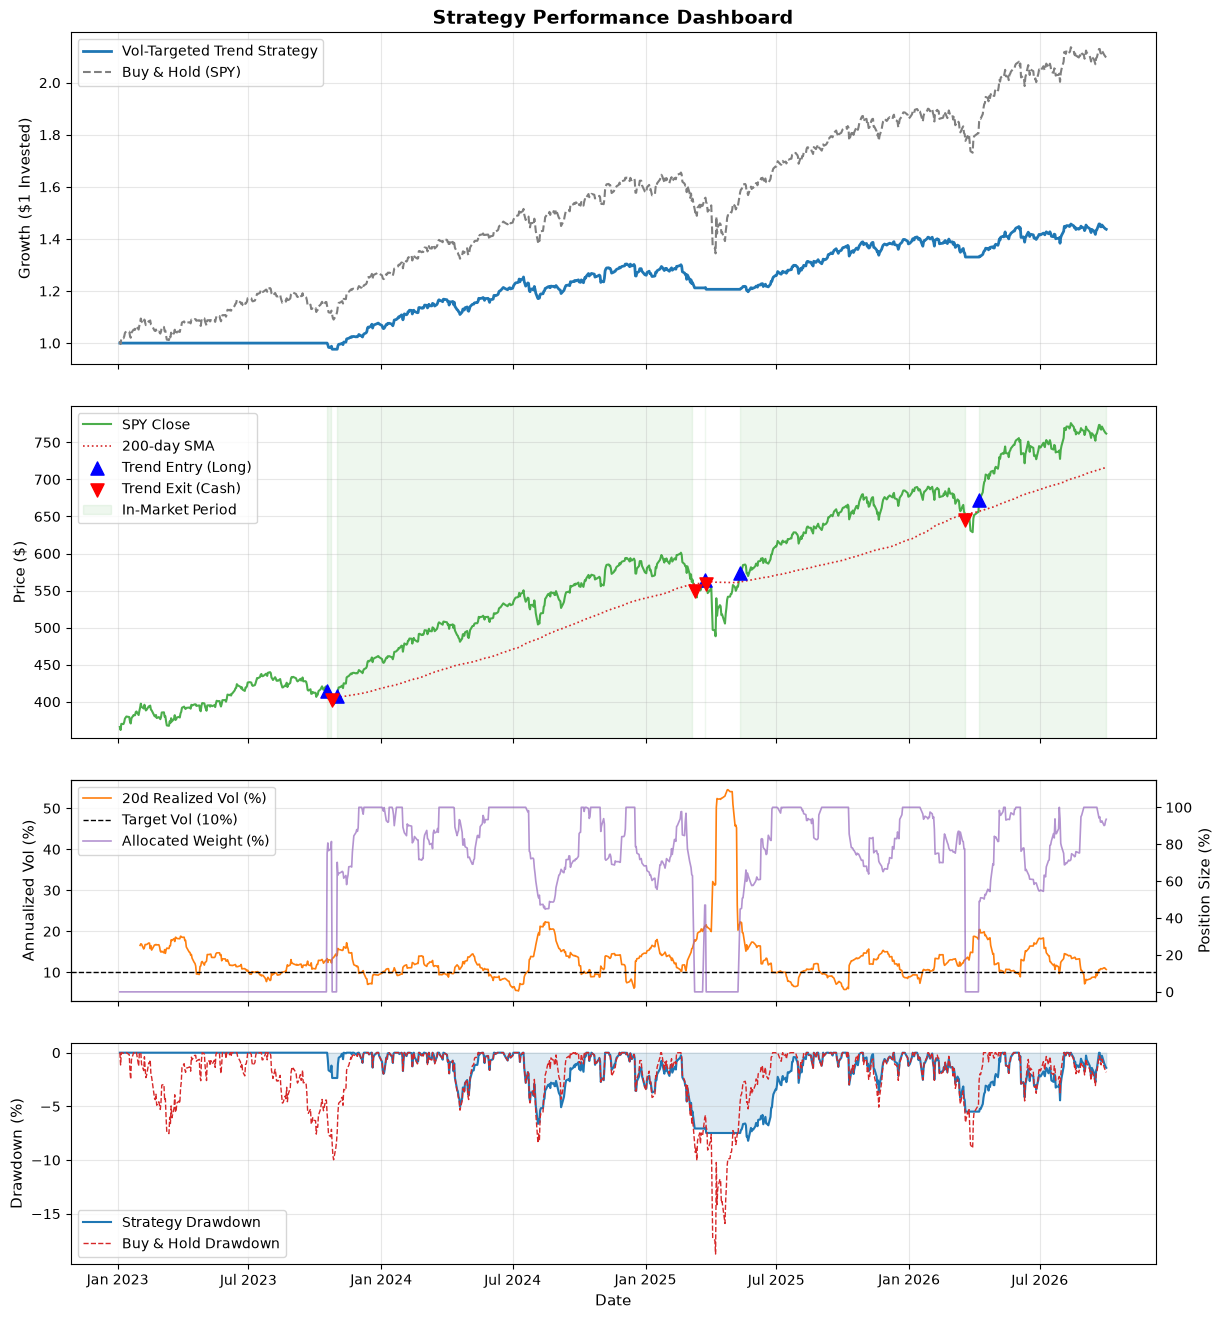

In [27]:
# 2. Build Dashboard
fig, axes = plt.subplots(4, 1, figsize=(14, 16), sharex=True, gridspec_kw={"height_ratios": [3, 3, 2, 2]})
plt.subplots_adjust(hspace=0.15)

# Panel 1: Equity Curve Comparison
axes[0].plot(df_clean.index, df_clean["Strat_Equity"], label="Vol-Targeted Trend Strategy", color="#1f77b4", lw=2)
axes[0].plot(df_clean.index, df_clean["BnH_Equity"], label="Buy & Hold (SPY)", color="#7f7f7f", lw=1.5, ls="--")
axes[0].set_ylabel("Growth ($1 Invested)", fontsize=11)
axes[0].set_title("Strategy Performance Dashboard", fontsize=14, weight="bold")
axes[0].grid(True, alpha=0.3)
axes[0].legend(loc="upper left")

# Panel 2: Price, SMA200 & Trade Execution Signals
axes[1].plot(df_clean.index, df_clean["Close"], label="SPY Close", color="#2ca02c", alpha=0.85, lw=1.5)
axes[1].plot(df_clean.index, df_clean["SMA200"], label="200-day SMA", color="#d62728", lw=1.2, ls=":")
axes[1].scatter(entries.index, entries["Close"], marker="^", color="blue", s=90, label="Trend Entry (Long)", zorder=5)
axes[1].scatter(exits.index, exits["Close"], marker="v", color="red", s=90, label="Trend Exit (Cash)", zorder=5)

# Shading periods where a long position is active
axes[1].fill_between(
    df_clean.index,
    df_clean["Close"].min() * 0.95,
    df_clean["Close"].max() * 1.05,
    where=(df_clean["Position"] > 0),
    color="#2ca02c",
    alpha=0.08,
    label="In-Market Period",
)
axes[1].set_ylim(df_clean["Close"].min() * 0.97, df_clean["Close"].max() * 1.03)
axes[1].set_ylabel("Price ($)", fontsize=11)
axes[1].grid(True, alpha=0.3)
axes[1].legend(loc="upper left")

# Panel 3: Volatility & Active Position Sizing
ax_vol = axes[2]
ax_weight = ax_vol.twinx()

p_vol = ax_vol.plot(df_clean.index, df_clean["Vol20"] * 100, label="20d Realized Vol (%)", color="#ff7f0e", lw=1.2)
p_tgt = ax_vol.axhline(target_vol * 100, color="black", ls="--", lw=1, label=f"Target Vol ({int(target_vol*100)}%)")
p_wt = ax_weight.plot(df_clean.index, df_clean["Position"] * 100, label="Allocated Weight (%)", color="#9467bd", lw=1.2, alpha=0.7)

ax_vol.set_ylabel("Annualized Vol (%)", fontsize=11)
ax_weight.set_ylabel("Position Size (%)", fontsize=11)
ax_weight.set_ylim(-5, 115)
ax_vol.grid(True, alpha=0.3)

# Combined legend for twin axes
lines = p_vol + [p_tgt] + p_wt
labels = [l.get_label() for l in lines]
ax_vol.legend(lines, labels, loc="upper left")

# Panel 4: Drawdowns
axes[3].plot(df_clean.index, df_clean["Strat_DD"] * 100, label="Strategy Drawdown", color="#1f77b4", lw=1.5)
axes[3].plot(df_clean.index, df_clean["BnH_DD"] * 100, label="Buy & Hold Drawdown", color="#d62728", lw=1, ls="--")
axes[3].fill_between(df_clean.index, df_clean["Strat_DD"] * 100, 0, color="#1f77b4", alpha=0.15)
axes[3].set_ylabel("Drawdown (%)", fontsize=11)
axes[3].set_xlabel("Date", fontsize=11)
axes[3].grid(True, alpha=0.3)
axes[3].legend(loc="lower left")

# Format date axis
axes[3].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.show()